# Generative Project – Milestone 1: Image Captioning Baseline

**Goal of the project:** build a model that looks at a photo and writes a caption for it.



### Step 0 – Install packages


In [1]:
%pip install -q transformers datasets

### Step 1 – Imports and settings


In [2]:
import os, re, random, json
from concurrent.futures import ThreadPoolExecutor
from io import BytesIO

import numpy as np
import pandas as pd
import requests
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from PIL import Image
from datasets import load_dataset
import transformers
from transformers import CLIPModel, CLIPProcessor, GPT2TokenizerFast, GPT2LMHeadModel

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = "cuda" if torch.cuda.is_available() else "cpu"
print("PyTorch:", torch.__version__, "| Transformers:", transformers.__version__, "| device:", device)

N_IMAGES   = 1000        # 1,000 images x ~5 captions = ~5,000 image-caption pairs
MIN_WORDS  = 5           # drop captions shorter than this
MAX_WORDS  = 25          # drop captions longer than this
MAX_TOKENS = 40          # GPT-2 token length after padding
CLIP_NAME  = "openai/clip-vit-base-patch32"
DATA_DIR   = "data"
IMG_DIR    = os.path.join(DATA_DIR, "images")
os.makedirs(IMG_DIR, exist_ok=True)

PyTorch: 2.14.1+cu130 | Transformers: 5.22.1 | device: cuda


### Step 2 - Choose the dataset: COCO Captions
 Download the COCO caption list (Karpathy split). Each row is one image with about 5 human-written captions and a link to the image. We randomly pick 1,000 images from the training part.



In [3]:
coco = load_dataset("yerevann/coco-karpathy", split="train")
print("Full COCO train split:", len(coco), "images")

idx = random.sample(range(len(coco)), N_IMAGES)
subset = coco.select(idx)
raw = pd.DataFrame({"image_id": subset["cocoid"], "url": subset["url"], "captions": subset["sentences"]})
print("Picked", len(raw), "images,", raw["captions"].str.len().sum(), "raw captions")
raw.head(3)

README.md:   0%|          | 0.00/246 [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 17.0MB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/validation-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 1.07MB            

data/validation-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 1.07MB            

... (5 outputs left out)

Generating test split:   0%|          | 0/5000 [00:00<?, ? examples/s]

Generating restval split:   0%|          | 0/30504 [00:00<?, ? examples/s]

Full COCO train split: 82783 images
Picked 1000 images, 5004 raw captions


,image_id,url,captions
0,243829,http://images.cocodataset.org/train2014/COCO_t...,[A little girl standing and facing a fence wit...
1,151124,http://images.cocodataset.org/train2014/COCO_t...,[A couple of women sitting next to each other ...
2,222970,http://images.cocodataset.org/train2014/COCO_t...,[A bus traveling down a city street next to pa...


### Step 3 - Clean the captions
 Make every caption lowercase, remove punctuation and extra spaces, then remove captions that are too short (< 5 words) or too long (> 25 words) and exact duplicates for the same image. This gives the tokenizer and the model clean, consistent text.

In [4]:
def clean_caption(text):
    text = text.lower().strip()
    text = re.sub(r"[^a-z0-9' ]+", " ", text)   # keep letters, numbers, apostrophes
    text = re.sub(r"\s+", " ", text).strip()     # collapse extra spaces
    return text

rows = []
dropped_short = dropped_long = dropped_dup = 0
for _, r in raw.iterrows():
    seen = set()
    for c in r["captions"]:
        c2 = clean_caption(c)
        n = len(c2.split())
        if n < MIN_WORDS:   dropped_short += 1; continue
        if n > MAX_WORDS:   dropped_long  += 1; continue
        if c2 in seen:      dropped_dup   += 1; continue
        seen.add(c2)
        rows.append({"image_id": r["image_id"], "url": r["url"], "raw": c, "caption": c2})

pairs = pd.DataFrame(rows)
print(f"Kept {len(pairs)} pairs | dropped: {dropped_short} too short, {dropped_long} too long, {dropped_dup} duplicates")
pairs[["raw", "caption"]].head(5)

Kept 4992 pairs | dropped: 0 too short, 9 too long, 3 duplicates


,raw,caption
0,A little girl standing and facing a fence with...,a little girl standing and facing a fence with...
1,A small girl looks on at the sheep in the fiel...,a small girl looks on at the sheep in the fiel...
2,A little girl looking across a road at a herd ...,a little girl looking across a road at a herd ...
3,A little girl in a green dress watching a herd...,a little girl in a green dress watching a herd...
4,A herder looking out at a herd of sheep,a herder looking out at a herd of sheep


### Step 4 – Download and check the images
Download the 1,000 images in parallel, convert every image to RGB (some COCO photos are black-and-white), and shrink the long side to 384 px to save space. If an image fails to download or open, we drop it and its captions.

In [5]:
def download(row):
    path = os.path.join(IMG_DIR, f"{row.image_id}.jpg")
    if os.path.exists(path):
        return row.image_id, path
    try:
        r = requests.get(row.url, timeout=20)
        img = Image.open(BytesIO(r.content)).convert("RGB")
        img.thumbnail((384, 384))
        img.save(path, quality=90)
        return row.image_id, path
    except Exception as e:
        return row.image_id, None

with ThreadPoolExecutor(max_workers=16) as ex:
    results = list(ex.map(download, raw.itertuples()))

path_of = {i: p for i, p in results if p is not None}
print("Downloaded:", len(path_of), "| failed:", len(results) - len(path_of))

pairs = pairs[pairs["image_id"].isin(path_of)].copy()
pairs["path"] = pairs["image_id"].map(path_of)
print("Image-caption pairs after image check:", len(pairs))

Downloaded: 1000 | failed: 0
Image-caption pairs after image check: 4992


### Step 5 - Split into train / validation / test by image
 Split the images 80/10/10. We split by image, not by caption, so the same photo never appears in both train and test (otherwise the test score would be too optimistic). Then we save the clean table to captions_clean.csv.

In [6]:
images = sorted(pairs["image_id"].unique())
rng = np.random.default_rng(SEED)
rng.shuffle(images)
n = len(images)
split_of = {}
for i, im in enumerate(images):
    split_of[im] = "train" if i < 0.8 * n else ("val" if i < 0.9 * n else "test")
pairs["split"] = pairs["image_id"].map(split_of)
pairs = pairs.reset_index(drop=True)   # row number = position in the token tensors later

print(pairs.groupby("split").agg(images=("image_id", "nunique"), pairs=("caption", "size")))
pairs.drop(columns=["url"]).to_csv(os.path.join(DATA_DIR, "captions_clean.csv"), index=False)

       images  pairs
split               
test      100    499
train     800   3993
val       100    500


### Step 6 – Look at the data
 Show 6 random images with one of their cleaned captions and a histogram of caption lengths in words.

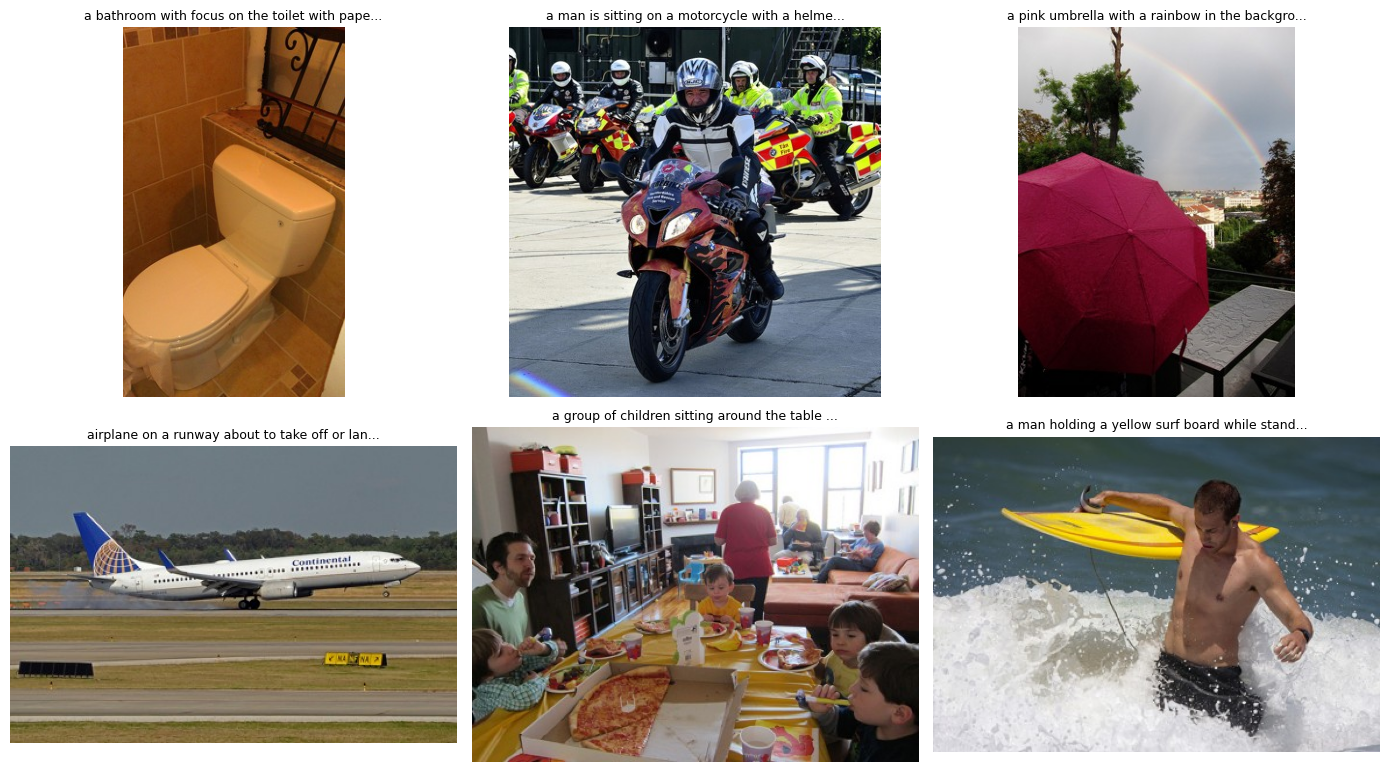

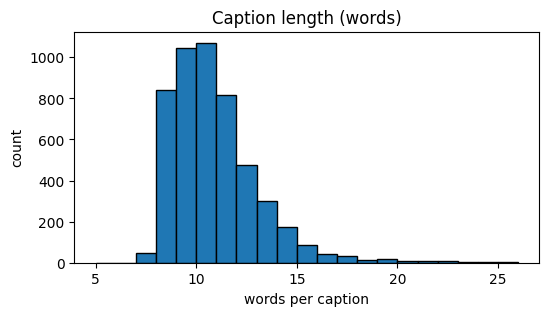

Words per caption: mean 10.4, min 6, max 25


In [7]:
show = pairs.drop_duplicates("image_id").sample(6, random_state=SEED)
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
for ax, (_, r) in zip(axes.ravel(), show.iterrows()):
    ax.imshow(Image.open(r["path"])); ax.axis("off")
    ax.set_title(r["caption"][:45] + ("..." if len(r["caption"]) > 45 else ""), fontsize=9)
plt.tight_layout()
plt.show()

words = pairs["caption"].str.split().str.len()
plt.figure(figsize=(6, 3))
plt.hist(words, bins=range(MIN_WORDS, MAX_WORDS + 2), edgecolor="black")
plt.xlabel("words per caption")
plt.ylabel("count")
plt.title("Caption length (words)")
plt.show()
print(f"Words per caption: mean {words.mean():.1f}, min {words.min()}, max {words.max()}")

### Step 7 – Image → CLIP embedding
Load CLIP (ViT-B/32) and turn every image into a 512-number vector (the image embedding). We normalise each vector to length 1, so comparing two vectors with a dot product gives the cosine similarity. CLIP is frozen (no training): it is only used as a feature extractor. The embeddings are saved to clip_image_embeddings.pt.

In [8]:
clip = CLIPModel.from_pretrained(CLIP_NAME).to(device).eval()
processor = CLIPProcessor.from_pretrained(CLIP_NAME)

def as_tensor(out):
    # newer Transformers versions may return an output object instead of a plain tensor
    return out if torch.is_tensor(out) else out.pooler_output

image_ids = list(path_of.keys())
embs = []
with torch.no_grad():
    for i in range(0, len(image_ids), 64):
        batch = [Image.open(path_of[j]) for j in image_ids[i:i + 64]]
        inputs = processor(images=batch, return_tensors="pt").to(device)
        e = as_tensor(clip.get_image_features(**inputs))
        embs.append(torch.nn.functional.normalize(e, dim=-1).cpu())
img_emb = torch.cat(embs)
emb_row = {im: k for k, im in enumerate(image_ids)}

print("Image embeddings:", tuple(img_emb.shape), "(images x 512)")
print("Length of first vector:", round(img_emb[0].norm().item(), 3))
torch.save({"image_ids": image_ids, "embeddings": img_emb}, os.path.join(DATA_DIR, "clip_image_embeddings.pt"))

config.json:   0%|          | 0.00/4.19k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  605MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  605MB            

model.safetensors: downloading bytes:           |  0.00B            

... (3 outputs left out)

merges.txt:   0%|          | 0.00/525k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.22M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/389 [00:00<?, ?B/s]

Image embeddings: (1000, 512) (images x 512)
Length of first vector: 1.0


### Step 8 - Sanity check: does CLIP match images to their own captions?
 Take 5 test images and one caption for each, embed the captions with CLIP's text encoder, and show the 5 × 5 similarity table. If the pipeline is right, each image should match its own caption best (highest number on the diagonal).

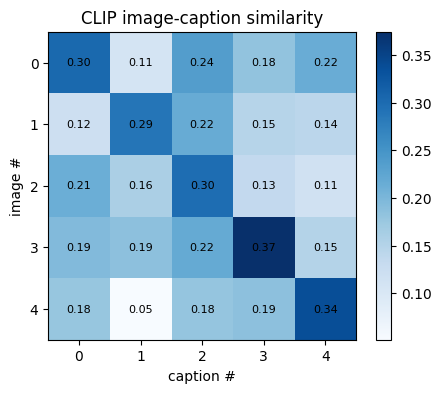

Each image matched its own caption: True


In [9]:
def embed_text(texts):
    out = []
    with torch.no_grad():
        for i in range(0, len(texts), 256):
            t = processor(text=texts[i:i + 256], return_tensors="pt", padding=True, truncation=True).to(device)
            out.append(torch.nn.functional.normalize(as_tensor(clip.get_text_features(**t)), dim=-1).cpu())
    return torch.cat(out)

check = pairs[pairs["split"] == "test"].drop_duplicates("image_id").head(5)
sim = img_emb[[emb_row[i] for i in check["image_id"]]] @ embed_text(check["caption"].tolist()).T

plt.figure(figsize=(5, 4))
plt.imshow(sim, cmap="Blues")
plt.colorbar()
for a in range(5):
    for b in range(5):
        plt.text(b, a, f"{sim[a, b]:.2f}", ha="center", va="center", fontsize=8)
plt.xlabel("caption #")
plt.ylabel("image #")
plt.title("CLIP image-caption similarity")
plt.show()
print("Each image matched its own caption:", bool((sim.argmax(dim=1) == torch.arange(5)).all()))

### Step 9 - Tokenize the captions with the GPT-2 tokenizer
 GPT-2 reads numbers (token ids), not words. The tokenizer splits each caption into sub-word pieces and gives each piece an id. GPT-2 has no padding token, so we use its end-of-text token (`<|endoftext|>`, id 50256) for padding and we add it at the end of every caption so the model learns when to stop. Every caption is padded or cut to 40 tokens, and the attention mask marks the real tokens (1) versus padding (0).

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

Caption : a little girl standing and facing a fence with animals behind it
Pieces  : ['a', 'Ġlittle', 'Ġgirl', 'Ġstanding', 'Ġand', 'Ġfacing', 'Ġa', 'Ġfence', 'Ġwith', 'Ġanimals', 'Ġbehind', 'Ġit', '<|endoftext|>']
Ids     : [64, 1310, 2576, 5055, 290, 6476, 257, 13990, 351, 4695, 2157, 340, 50256]

Tokens per caption (incl. end token): mean 12.0, max 28
Captions longer than 40 tokens (would be cut): 0
input_ids: (4992, 40) | attention_mask: (4992, 40)


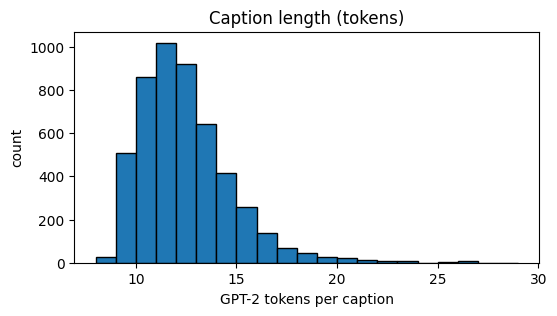

In [10]:
tokenizer = GPT2TokenizerFast.from_pretrained("gpt2")
tokenizer.pad_token = tokenizer.eos_token

example = pairs["caption"].iloc[0]
ids = tokenizer(example + tokenizer.eos_token)["input_ids"]
print("Caption :", example)
print("Pieces  :", tokenizer.convert_ids_to_tokens(ids))
print("Ids     :", ids)

lengths = [len(tokenizer(c + tokenizer.eos_token)["input_ids"]) for c in pairs["caption"]]
print(f"\nTokens per caption (incl. end token): mean {np.mean(lengths):.1f}, max {max(lengths)}")
print(f"Captions longer than {MAX_TOKENS} tokens (would be cut): {sum(l > MAX_TOKENS for l in lengths)}")

enc = tokenizer([c + tokenizer.eos_token for c in pairs["caption"]], padding="max_length",
                truncation=True, max_length=MAX_TOKENS, return_tensors="pt")
print("input_ids:", tuple(enc["input_ids"].shape), "| attention_mask:", tuple(enc["attention_mask"].shape))

plt.figure(figsize=(6, 3))
plt.hist(lengths, bins=range(min(lengths), max(lengths) + 2), edgecolor="black")
plt.xlabel("GPT-2 tokens per caption")
plt.ylabel("count")
plt.title("Caption length (tokens)")
plt.show()

torch.save({"image_ids": pairs["image_id"].tolist(), "split": pairs["split"].tolist(),
            "input_ids": enc["input_ids"], "attention_mask": enc["attention_mask"]},
           os.path.join(DATA_DIR, "gpt2_tokens.pt"))

### Step 10 - 5 sample image → caption test runs (baseline)
 Before training anything, we make a simple baseline captioner: for a test image, it searches all training captions and returns the one whose CLIP text embedding is closest to the image embedding. This uses only the pipeline built above (image → embedding). We run it on 5 test images and show the true caption next to the baseline caption with the CLIP similarity. The trained ClipCap model in the next milestone should beat this baseline by writing new captions instead of copying existing ones.

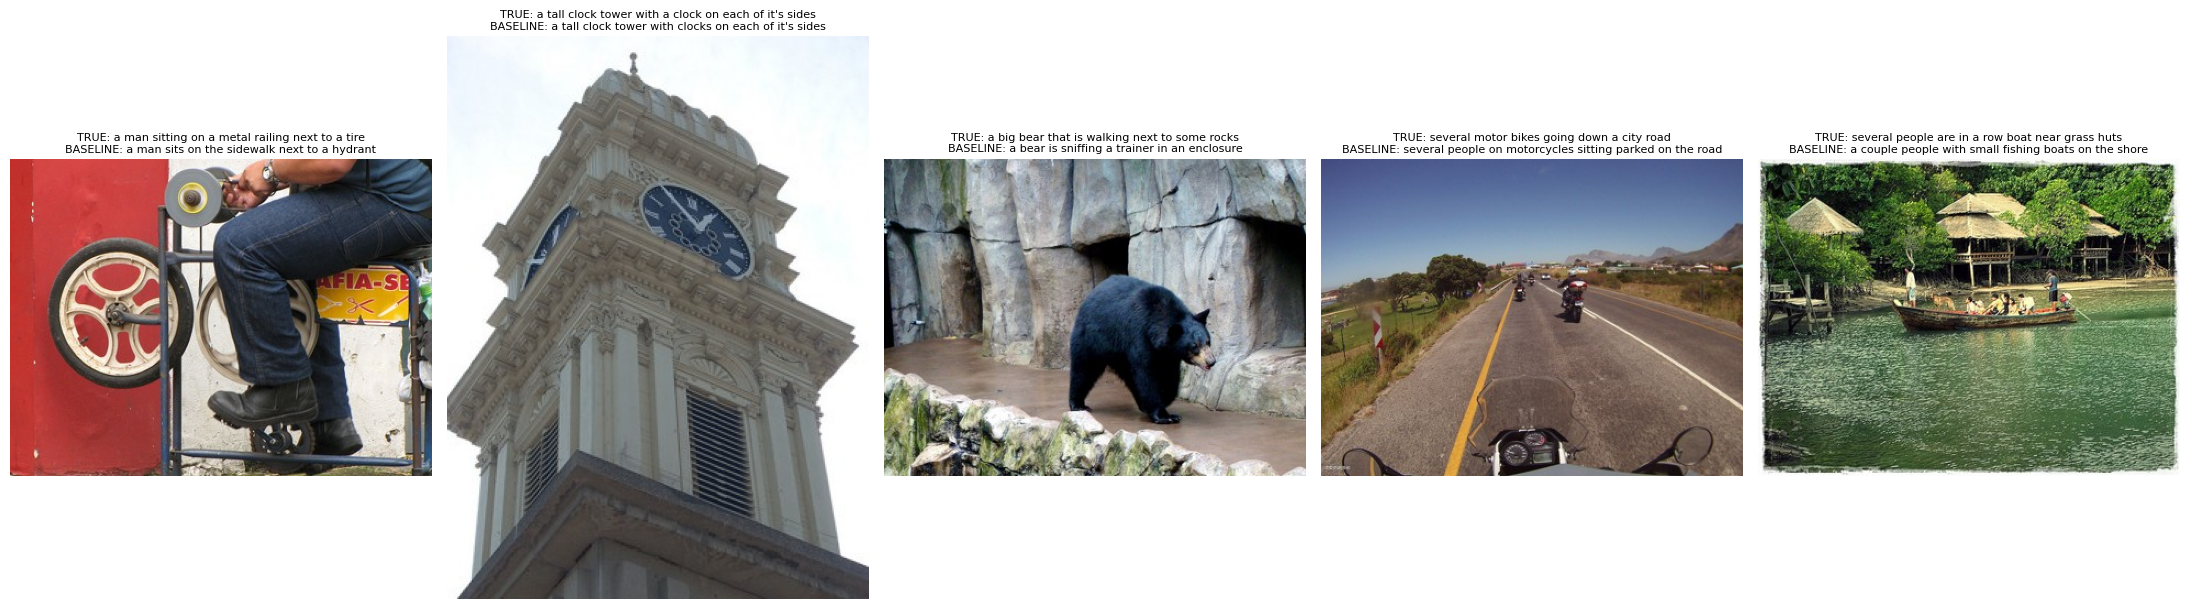

,image_id,true caption,baseline caption,CLIP similarity
0,93451,a man sitting on a metal railing next to a tire,a man sits on the sidewalk next to a hydrant,0.281
1,443988,a tall clock tower with a clock on each of it'...,a tall clock tower with clocks on each of it's...,0.360
2,180046,a big bear that is walking next to some rocks,a bear is sniffing a trainer in an enclosure,0.329
3,37779,several motor bikes going down a city road,several people on motorcycles sitting parked o...,0.326
4,229522,several people are in a row boat near grass huts,a couple people with small fishing boats on th...,0.286


In [11]:
train_caps = pairs[pairs["split"] == "train"]["caption"].tolist()
train_txt_emb = embed_text(train_caps)

runs = pairs[pairs["split"] == "test"].drop_duplicates("image_id").sample(5, random_state=SEED)
fig, axes = plt.subplots(1, 5, figsize=(22, 6))
results = []
for ax, (_, r) in zip(axes, runs.iterrows()):
    scores = img_emb[emb_row[r["image_id"]]] @ train_txt_emb.T
    best = scores.argmax().item()
    results.append({"image_id": r["image_id"], "true caption": r["caption"],
                    "baseline caption": train_caps[best], "CLIP similarity": round(scores[best].item(), 3)})
    ax.imshow(Image.open(r["path"]))
    ax.axis("off")
    ax.set_title(f"TRUE: {r['caption']}\nBASELINE: {train_caps[best]}", fontsize=8, wrap=True)
plt.tight_layout()
plt.savefig("data/sample_5_runs.png", dpi=150, bbox_inches="tight")
plt.show()

test_runs = pd.DataFrame(results)
test_runs.to_csv(os.path.join(DATA_DIR, "sample_test_runs.csv"), index=False)
test_runs

### Step 11 - Pipeline check for the model (CLIP prefix → GPT-2)
 Build the untrained version of the model we plan to train in the next milestone, to check that all the shapes connect. A small mapping network (MLP) turns one 512-number CLIP vector into 10 "prefix" vectors of size 768 (GPT-2's embedding size). The prefix is placed in front of the caption's token embeddings and GPT-2 computes the next-word loss on the caption tokens only. Nothing is trained here, so the loss is high.

In [12]:
PREFIX_LEN = 10
gpt2 = GPT2LMHeadModel.from_pretrained("gpt2").to(device).eval()
emb_size = gpt2.config.n_embd   # 768

mapper = nn.Sequential(
    nn.Linear(512, (emb_size * PREFIX_LEN) // 2), nn.Tanh(),
    nn.Linear((emb_size * PREFIX_LEN) // 2, emb_size * PREFIX_LEN),
).to(device)

b = pairs[pairs["split"] == "train"].head(4)
tok = enc["input_ids"][b.index].to(device)
mask = enc["attention_mask"][b.index].to(device)
clip_vec = img_emb[[emb_row[i] for i in b["image_id"]]].to(device)

with torch.no_grad():
    prefix = mapper(clip_vec).view(-1, PREFIX_LEN, emb_size)          # (4, 10, 768)
    tok_emb = gpt2.transformer.wte(tok)                                # (4, 40, 768)
    inputs_embeds = torch.cat([prefix, tok_emb], dim=1)                # (4, 50, 768)
    full_mask = torch.cat([torch.ones(len(b), PREFIX_LEN, device=device), mask], dim=1)
    labels = torch.cat([torch.full((len(b), PREFIX_LEN), -100, device=device),
                        tok.masked_fill(mask == 0, -100)], dim=1)      # no loss on prefix or padding
    out = gpt2(inputs_embeds=inputs_embeds, attention_mask=full_mask, labels=labels)

print("CLIP vectors :", tuple(clip_vec.shape))
print("Prefix       :", tuple(prefix.shape))
print("Caption embs :", tuple(tok_emb.shape))
print("GPT-2 input  :", tuple(inputs_embeds.shape))
print(f"Untrained loss: {out.loss.item():.2f}  (random guessing over 50,257 tokens = ln(50257) = {np.log(50257):.2f})")
print("Mapping network parameters:", f"{sum(p.numel() for p in mapper.parameters()):,}")

config.json:   0%|          | 0.00/665 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  548MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

[transformers] `loss_type=None` was set in the config but it is unrecognized. Using the default loss: `ForCausalLMLoss`.


CLIP vectors : (4, 512)
Prefix       : (4, 10, 768)
Caption embs : (4, 40, 768)
GPT-2 input  : (4, 50, 768)
Untrained loss: 9.31  (random guessing over 50,257 tokens = ln(50257) = 10.82)
Mapping network parameters: 31,468,800


### Step 12 - Saved files
List the files this notebook produced

In [13]:
for f in sorted(os.listdir(DATA_DIR)):
    p = os.path.join(DATA_DIR, f)
    if os.path.isfile(p):
        print(f"{f:32s} {os.path.getsize(p) / 1e6:6.2f} MB")
print(f"images/ folder: {len(os.listdir(IMG_DIR))} images")

captions_clean.csv                 0.70 MB
clip_image_embeddings.pt           2.05 MB
gpt2_tokens.pt                     3.23 MB
sample_5_runs.png                  2.55 MB
sample_test_runs.csv               0.00 MB
images/ folder: 1000 images


## Observations
- Dataset: We picked 1,000 random COCO images (5,004 raw captions). Cleaning removed only 12 captions (9 longer than 25 words, 3 exact duplicates, none too short), leaving 4,992 image–caption pairs. All 1,000 images downloaded and opened correctly. Split by image: 800 train/100 val/100 test images (3,993/500/499 pairs).
- Captions: on average 10.4 words and 12.0 GPT-2 tokens (including the end token); the longest is 28 tokens, so no caption is cut at the 40-token limit.
- CLIP embeddings: every image became a 512-number vector of length 1.0. In the 5 × 5 check, every image matched its own caption best (diagonal 0.29–0.37 vs. 0.05–0.24 off-diagonal), so the image → embedding pipeline works.
- Baseline test runs: the retrieval baseline got the main object right in all 5 images (man, clock tower, bear, motorbikes, boat) but often the wrong details (hydrant instead of tire, "parked" instead of "going down the road"). The clock-tower caption is almost identical because COCO has very similar clock-tower photos in the training set. The limit of this baseline is that it can only copy an existing caption; it cannot write a new one.
- Pipeline check: the untrained CLIP-prefix → GPT-2 model gives a loss of **9.31**, close to random guessing (ln 50,257 ≈ 10.82). This is expected because the mapping network (31.5M parameters) is not trained yet. All shapes connect: (4, 512) → prefix (4, 10, 768) + caption (4, 40, 768) → GPT-2 input (4, 50, 768).
